# Easy Motion — виртуальный коуч

Цель: сравнить положение тела на референсном видео и на моей записи, получить скелеты, расстояния между позами и видео для просмотра.

Это пример использования проекта. Основной код находится в четырёх небольших пакетах в `src/`. Модель Keypoint R-CNN уже обучена на COCO; здесь она применяется без дополнительного обучения.

In [1]:
from pathlib import Path
import sys
import csv
import json
import numpy as np
from IPython.display import Image, Markdown, Video, display

from easy_motion_data import VideoDataset, make_pairs
from easy_motion.metrics import cosine_distance, weighted_distance

ROOT = Path.cwd()
if not (ROOT / "data").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "pyproject.toml").is_file(), "Запустите ноутбук из папки проекта или examples"

# Общий сценарий находится в scripts/, отдельно от четырёх пакетов.
sys.path.insert(0, str(ROOT / "scripts"))
from pipeline import run_project

REFERENCE = ROOT / "data" / "reference_video.mp4"
MY_VIDEO = ROOT / "data" / "my.mp4"
OUTPUT = ROOT / "results"
print("Файлы:", REFERENCE.name, "и", MY_VIDEO.name)

Файлы: reference_video.mp4 и my.mp4


## 1. Данные и сопоставление времени

Референс длится 3 секунды, моя запись — 4 секунды. Это два демонстрационных видео, а не обучающая и тестовая выборки. Загрузчик читает RGB-кадры, проверяет FPS и временные метки.

Основной режим `relative` сопоставляет 120 равных долей полного движения. Контрольный `realtime` сравнивает одинаковые моменты времени на общем интервале 0–3 секунды, без изменения темпа. В нём последняя секунда моей записи не участвует.

In [2]:
reference = VideoDataset(REFERENCE)
execution = VideoDataset(MY_VIDEO)
for video in (reference, execution):
    print(video.describe())
for mode in ("relative", "realtime"):
    pairs, fps = make_pairs(reference, execution, mode)
    print(f"{mode}: {len(pairs)} пар, выходное видео {fps:g} FPS")
# Основная функция сама загрузит видео: освобождаем кадры этого примера.
del reference, execution

{'file': 'reference_video.mp4', 'width': 720, 'height': 1280, 'fps': 60.0, 'frames': 180, 'duration_s': 3.0}
{'file': 'my.mp4', 'width': 480, 'height': 854, 'fps': 30.0, 'frames': 120, 'duration_s': 4.0}
relative: 120 пар, выходное видео 30 FPS
realtime: 90 пар, выходное видео 30 FPS


## 2. Что делает программа

1. Keypoint R-CNN предсказывает 17 точек тела в каждом кадре.
2. Сохраняются люди с оценкой детектора выше 0,9. В референсе выбирается человек справа (центр рамки ≥ 40% ширины), чтобы исключить манекен.
3. Если минимальный score шести точек ног ниже 4 или геометрия ног неоднозначна, модель дополнительно получает кадр с поворотами −40°, −20°, 20° и 40°. Углы, выводящие рамку спортсмена за границы кадра, пропускаются. Из геометрически допустимых поз выбирается вариант с наибольшим минимальным score ног, координаты возвращаются в исходный кадр.
4. Для каждой пары берутся общие точки с оценкой выше 2, обязательно все шесть точек обеих ног. Это сырой балл модели, а не вероятность.
5. Координаты моей позы аффинно совмещаются с референсом методом наименьших квадратов. Затем считаются косинусное расстояние и взвешенное L1.
6. Создаются CSV, JSON, график и два MP4. Недостаточно надёжные пары получают статус пропуска; им не присваивается нулевое расстояние.

Полная последовательность видна в `scripts/pipeline.py`; формулы отдельно в `src/easy_motion/metrics.py`.

Геометрическая проверка отсеивает почти совпавшие колени и голеностопы (расстояния < 20% длины корпуса), а также случаи, когда бедро или голень короче четверти соседнего сегмента. 

In [3]:
summary = run_project(REFERENCE, MY_VIDEO, OUTPUT)

reference_video.mp4: 60/180 кадров


reference_video.mp4: 120/180 кадров


reference_video.mp4: 180/180 кадров


my.mp4: 60/120 кадров


my.mp4: 120/120 кадров


relative: 79/120 пар; d_cos=0.002413; L1=56.373 px
realtime: 60/90 пар; d_cos=0.000934; L1=35.612 px


## 3. Проверим смысл расстояний на простом примере

Косинусное расстояние равно `1 − cos(a, b)`: для сонаправленных векторов оно равно 0, для перпендикулярных — 1. Взвешенное L1 — средняя по точкам сумма модулей ошибок x и y с весами надёжности. Оно измеряется в пикселях референса.

In [4]:
print("Одинаковое направление:", cosine_distance([1, 0], [2, 0]))
print("Перпендикулярные векторы:", cosine_distance([1, 0], [0, 1]))

target = np.array([[0, 0], [0, 0]], dtype=float)
predicted = np.array([[1, 2], [3, 4]], dtype=float)
weights = np.array([1, 3], dtype=float)
# (1 * (1 + 2) + 3 * (3 + 4)) / (1 + 3) = 6
print("Пример взвешенного L1:", weighted_distance(target, predicted, weights))

Одинаковое направление: 0.0
Перпендикулярные векторы: 1.0
Пример взвешенного L1: 6.0


## 4. Реальные результаты

Чем меньше расстояние, тем ближе координаты **после совмещения**. Средние считаются только по валидным парам. Дополнительно сохранено косинусное расстояние после вычитания центров поз: оно помогает заметить влияние общего положения относительно начала координат.

| Режим | Валидных пар | Среднее d_cos | Среднее L1, px | Центрированное d_cos |
|---|---:|---:|---:|---:|
| relative | 79/120 | 0.002413 | 56.373 | 0.077868 |
| realtime | 60/90 | 0.000934 | 35.612 | 0.032990 |

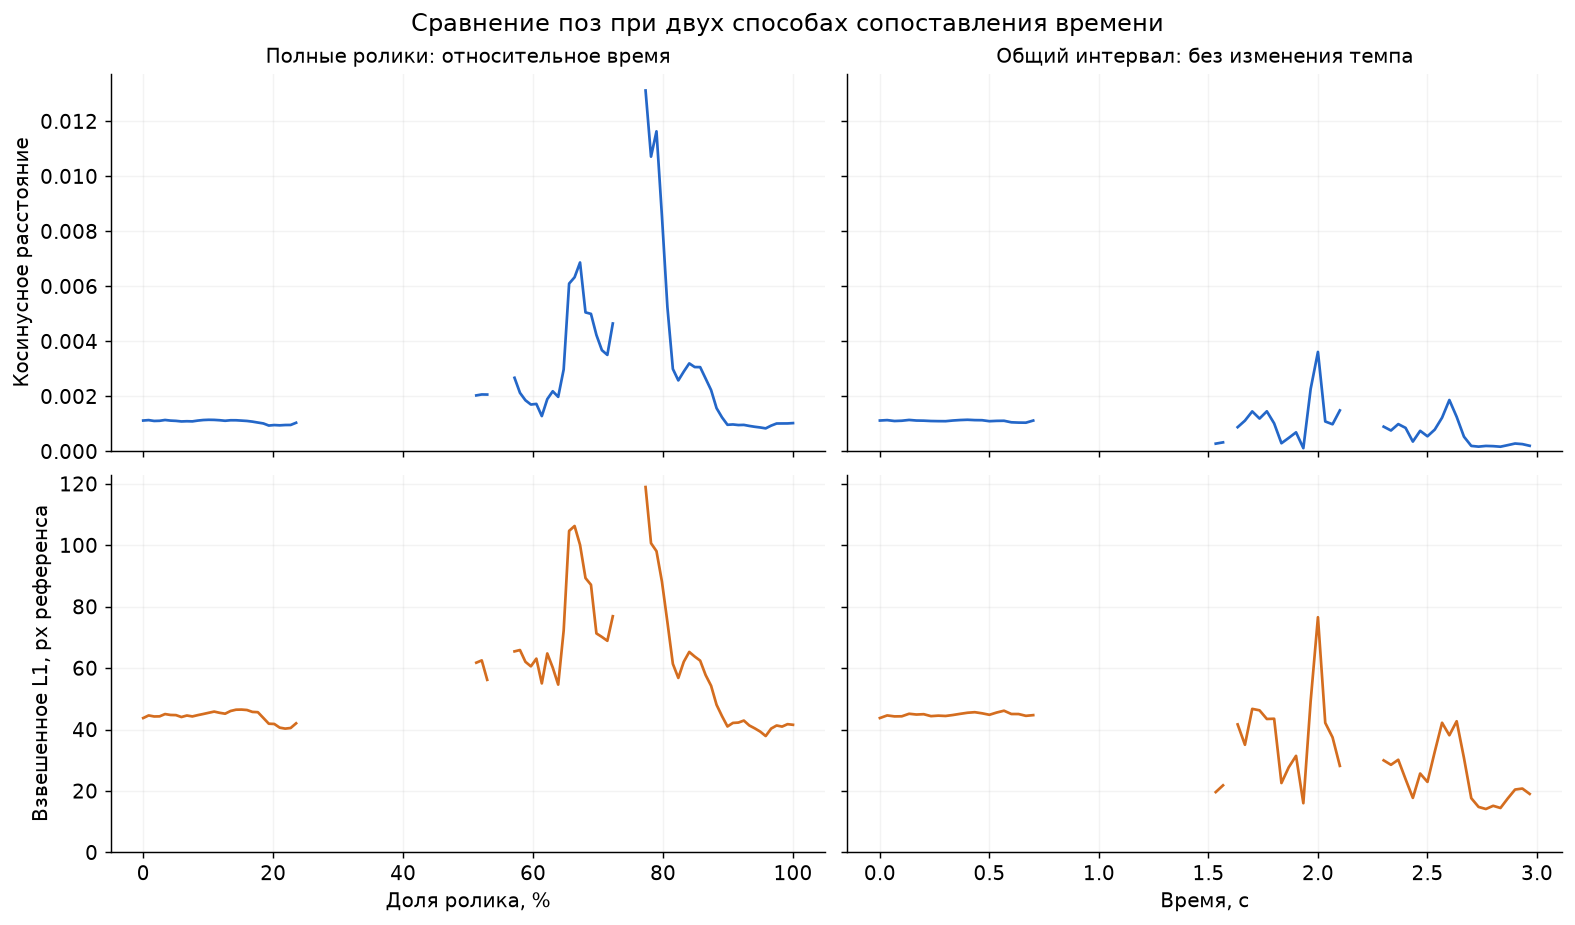

In [5]:
rows = ["| Режим | Валидных пар | Среднее d_cos | Среднее L1, px | Центрированное d_cos |",
        "|---|---:|---:|---:|---:|"]
for mode, result in summary["results"].items():
    rows.append(f"| {mode} | {result['valid_pairs']}/{result['pair_count']} | "
                f"{result['cosine_distance']['mean']:.6f} | "
                f"{result['weighted_l1_px']['mean']:.3f} | "
                f"{result['centered_cosine_distance']['mean']:.6f} |")
display(Markdown("\n".join(rows)))
display(Image(filename=str(OUTPUT / "metrics.png"), width=950))

## 5. Визуальная проверка

В каждом кадре показаны исходные люди со своими скелетами и общие метрики пары. Для рисования скелет сохраняет исходные координаты; аффинное преобразование используется при вычислении расстояний. Изображения масштабируются пропорционально, без растяжения.

Повторное распознавание исправляет пропущенную поднятую ногу на кадре 2,30 с. Если обе ноги всё ещё не определены надёжно, на видео показано «Нет оценки», а в графике остаётся разрыв. Высокий score сам по себе не гарантирует правильные координаты.

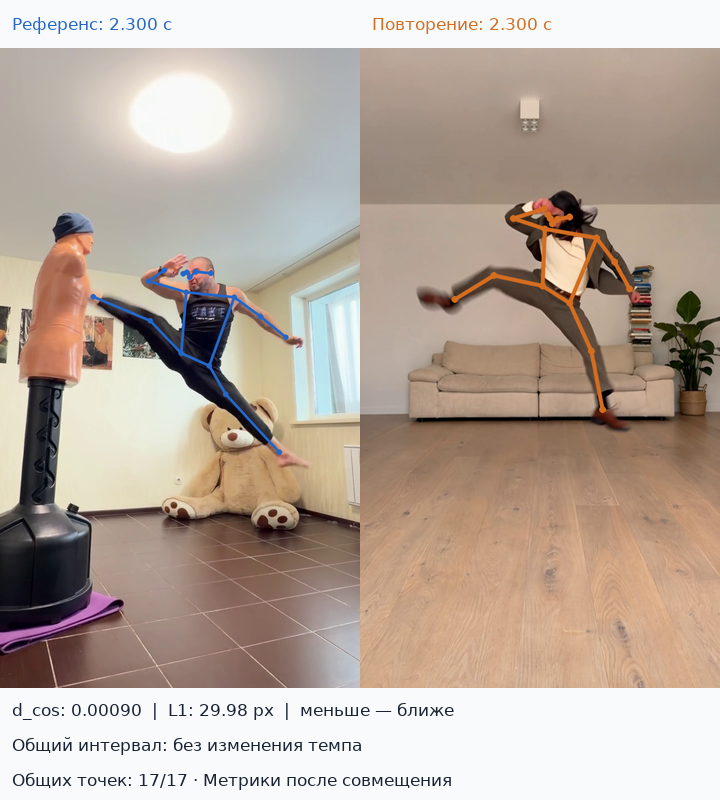

**Основной режим: по доле полного движения**

**Контрольный режим: общее время без изменения темпа**

In [6]:
display(Image(filename=str(OUTPUT / "demo.png"), width=540))
display(Markdown("**Основной режим: по доле полного движения**"))
display(Video(filename=str(OUTPUT / "relative" / "comparison.mp4"), embed=True, width=540))
display(Markdown("**Контрольный режим: общее время без изменения темпа**"))
display(Video(filename=str(OUTPUT / "realtime" / "comparison.mp4"), embed=True, width=540))

## 6. Проверка сохранённых результатов

Проверяем структуру CSV и конечность чисел для валидных пар. Пропущенные пары могут иметь пустые метрики. Математические функции дополнительно проверяются командой `python -m unittest discover -s tests -v` из корня проекта.

In [7]:
for mode, result in summary["results"].items():
    with (OUTPUT / mode / "frame_metrics.csv").open(encoding="utf-8-sig", newline="") as file:
        records = list(csv.DictReader(file))
    assert len(records) == result["pair_count"]
    valid = [row for row in records if row["status"] == "ok"]
    assert len(valid) == result["valid_pairs"]
    assert all(np.isfinite(float(row["weighted_l1_px"])) for row in valid)
    assert all(not row["weighted_l1_px"] for row in records if row["status"] != "ok")
    assert (OUTPUT / mode / "comparison.mp4").stat().st_size > 0
    print(mode, "— CSV и видео сохранены; валидных пар:", len(valid))
assert json.loads((OUTPUT / "summary.json").read_text(encoding="utf-8")) == summary

relative — CSV и видео сохранены; валидных пар: 79


realtime — CSV и видео сохранены; валидных пар: 60


## Вывод

Результаты обоих режимов приведены в таблице выше. Средние учитывают только пары, где надёжно определены обе ноги. Пропуски сохраняются в CSV и явно отмечены на видео.

Повторное распознавание повёрнутых кадров восстановило поднятую ногу на проверенном кадре 2,30 с. Это улучшение демонстрационного примера, а не доказательство точности модели на новых видео. Параметры выбраны при просмотре этих записей.

По числам нельзя объявить один режим «точнее»: режимы сравнивают разные пары и разные части записей. Низкое расстояние не равно проценту правильности техники. Полное аффинное преобразование допускает отражение и может скрывать различия движений.

Ограничения: две записи, двумерные точки, перекрытия тела, зависимость от ракурса, нет экспертной разметки правильности. Следующие шаги — ограничить преобразование, добавить углы суставов, временное выравнивание и больше размеченных примеров. Подробнее: `docs/METHOD.md` и `docs/EXPERIMENTS.md`.